In [7]:
import pandas as pd
import numpy as np
import gradio as gr
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [8]:
df = pd.read_csv('EarthquakeData.csv')

In [9]:
#New_Column_Name=('Target_Column', 'Function')
type_summary = df.groupby('Type').agg(
    Total_Events=('Magnitude', 'count'),
    Avg_Magnitude=('Magnitude', 'mean'),
    Max_Magnitude=('Magnitude', 'max'),
    Avg_Depth_km=('Depth', 'mean')
).reset_index()

print(type_summary)

                Type  Total_Events  Avg_Magnitude  Max_Magnitude  Avg_Depth_km
0         Earthquake         23232       5.882763            9.1     71.313913
1          Explosion             4       5.850000            6.4      0.000000
2  Nuclear Explosion           175       5.850686            6.9      0.300000
3         Rock Burst             1       6.200000            6.2      1.000000


In [10]:
'''
pd.to_datetime(df['Date'], errors='coerce', utc=True)

df['Date']: Selects the column containing the original date values.

errors='coerce': Automatically converts any unparseable or invalid date entries (e.g., bad text strings) into NaT (Not a Time) instead of throwing an error.

utc=True: Standardizes all dates to the UTC time zone before processing.(Coordinated Universal Time)

.dt.year

Uses the pandas datetime accessor (.dt) to extract just the year component (e.g., 2024) from each datetime object.

.astype('Int64')

Casts the year values to pandas' nullable integer data type (capitalized 'Int64').

Why this is used: Standard NumPy integers (int64 with a lowercase i) cannot hold missing values (NaN/NaT). Without Int64, any missing date in your dataset would force the entire year column to convert to floating-point numbers (e.g., 2024.0). 'Int64' preserves whole numbers while representing missing years cleanly as <NA>.

df['Year'] = ...

Assigns the processed year values into a column named 'Year' in the DataFrame.
'''
df['Year'] = pd.to_datetime(
    df['Date'], errors='coerce', utc=True
).dt.year.astype('Int64')
df

,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Azimuthal Gap,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status,Year
0,01/02/1965,13:44:18,19.2460,145.6160,Earthquake,131.60,NaN,NaN,6.0,MW,...,NaN,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
1,01/04/1965,11:29:49,1.8630,127.3520,Earthquake,80.00,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
2,01/05/1965,18:05:58,-20.5790,-173.9720,Earthquake,20.00,NaN,NaN,6.2,MW,...,NaN,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
3,01/08/1965,18:49:43,-59.0760,-23.5570,Earthquake,15.00,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
4,01/09/1965,13:32:50,11.9380,126.4270,Earthquake,15.00,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic,1965
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23407,12/28/2016,08:22:12,38.3917,-118.8941,Earthquake,12.30,1.2,40.0,5.6,ML,...,42.47,0.120,NaN,0.1898,NN00570710,NN,NN,NN,Reviewed,2016
23408,12/28/2016,09:13:47,38.3777,-118.8957,Earthquake,8.80,2.0,33.0,5.5,ML,...,48.58,0.129,NaN,0.2187,NN00570744,NN,NN,NN,Reviewed,2016
23409,12/28/2016,12:38:51,36.9179,140.4262,Earthquake,10.00,1.8,NaN,5.9,MWW,...,91.00,0.992,4.8,1.5200,US10007NAF,US,US,US,Reviewed,2016
23410,12/29/2016,22:30:19,-9.0283,118.6639,Earthquake,79.00,1.8,NaN,6.3,MWW,...,26.00,3.553,6.0,1.4300,US10007NL0,US,US,US,Reviewed,2016


In [11]:
annual_avg = df.groupby('Year')['Magnitude'].mean().reset_index().rename(columns={'Magnitude': 'Annual_Avg_Mag'})
annual_avg

,Year,Annual_Avg_Mag
0,1965,6.014159
1,1966,6.040470
2,1967,6.003922
3,1968,6.078525
4,1969,6.009350
5,1970,6.035768
6,1971,5.972539
7,1972,5.943814
8,1973,5.814065
9,1974,5.830332


In [12]:
df_merged = pd.merge(df, annual_avg, on='Year', how='left')
df_merged

,Date,Time,Latitude,Longitude,Type,Depth,Depth Error,Depth Seismic Stations,Magnitude,Magnitude Type,...,Horizontal Distance,Horizontal Error,Root Mean Square,ID,Source,Location Source,Magnitude Source,Status,Year,Annual_Avg_Mag
0,01/02/1965,13:44:18,19.2460,145.6160,Earthquake,131.60,NaN,NaN,6.0,MW,...,NaN,NaN,NaN,ISCGEM860706,ISCGEM,ISCGEM,ISCGEM,Automatic,1965,6.014159
1,01/04/1965,11:29:49,1.8630,127.3520,Earthquake,80.00,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,ISCGEM860737,ISCGEM,ISCGEM,ISCGEM,Automatic,1965,6.014159
2,01/05/1965,18:05:58,-20.5790,-173.9720,Earthquake,20.00,NaN,NaN,6.2,MW,...,NaN,NaN,NaN,ISCGEM860762,ISCGEM,ISCGEM,ISCGEM,Automatic,1965,6.014159
3,01/08/1965,18:49:43,-59.0760,-23.5570,Earthquake,15.00,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,ISCGEM860856,ISCGEM,ISCGEM,ISCGEM,Automatic,1965,6.014159
4,01/09/1965,13:32:50,11.9380,126.4270,Earthquake,15.00,NaN,NaN,5.8,MW,...,NaN,NaN,NaN,ISCGEM860890,ISCGEM,ISCGEM,ISCGEM,Automatic,1965,6.014159
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23407,12/28/2016,08:22:12,38.3917,-118.8941,Earthquake,12.30,1.2,40.0,5.6,ML,...,0.120,NaN,0.1898,NN00570710,NN,NN,NN,Reviewed,2016,5.892836
23408,12/28/2016,09:13:47,38.3777,-118.8957,Earthquake,8.80,2.0,33.0,5.5,ML,...,0.129,NaN,0.2187,NN00570744,NN,NN,NN,Reviewed,2016,5.892836
23409,12/28/2016,12:38:51,36.9179,140.4262,Earthquake,10.00,1.8,NaN,5.9,MWW,...,0.992,4.8,1.5200,US10007NAF,US,US,US,Reviewed,2016,5.892836
23410,12/29/2016,22:30:19,-9.0283,118.6639,Earthquake,79.00,1.8,NaN,6.3,MWW,...,3.553,6.0,1.4300,US10007NL0,US,US,US,Reviewed,2016,5.892836


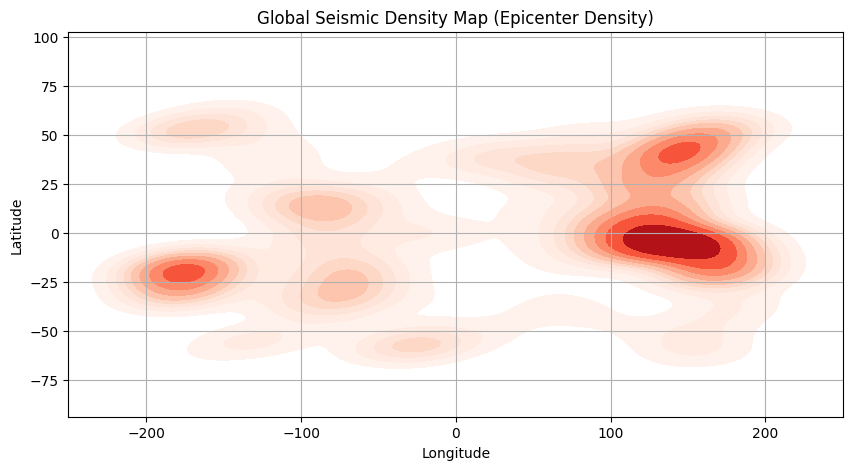

In [13]:
'''data=df: Specifies the pandas DataFrame (df) containing the dataset.

x='Longitude': Maps the horizontal axis to the DataFrame's 'Longitude' column.

y='Latitude': Maps the vertical axis to the DataFrame's 'Latitude' column.

cmap='Reds': Applies a red color map gradient where darker red indicates higher point density (frequent earthquake epicenters).

fill=True: Fills the density contour levels with solid color shading rather than drawing bare outline paths.

thresh=0.05: Sets the minimum density threshold at 5%, leaving low-density background areas transparent instead of covering the entire plot with light shading.'''


# 2D Density Plot (Geographic Hotspots)
plt.figure(figsize=(10, 5))
sns.kdeplot(data=df, x='Longitude', y='Latitude', cmap='Reds', fill=True, thresh=0.05)
plt.title('Global Seismic Density Map (Epicenter Density)')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True)
plt.show()

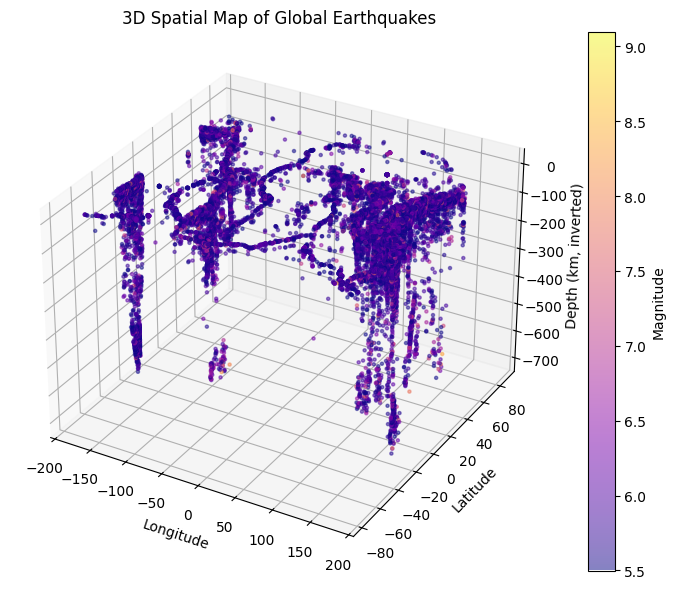

In [14]:
'''
df['Longitude']: Assigns horizontal X-axis coordinates.

df['Latitude']: Assigns horizontal Y-axis coordinates.

-df['Depth']: Assigns vertical Z-axis coordinates. The negative sign (-) inverts the depth so deeper earthquakes plot lower down, realistically representing underground depth below sea level.

c=df['Magnitude']: Colors each marker dynamically based on earthquake magnitude.

cmap='plasma': Applies the 'plasma' colormap gradient (ranging from dark purple to bright yellow) to visualize magnitude intensity.

alpha=0.5: Sets point transparency to 50% so dense, overlapping clusters remain visible.

s=5: Sets marker point size to 5 square points for a clean, non-cluttered view.



'''




fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(df['Longitude'], df['Latitude'], -df['Depth'], c=df['Magnitude'], cmap='plasma', alpha=0.5, s=5)
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_zlabel('Depth (km, inverted)')
plt.colorbar(sc, label='Magnitude')
plt.title('3D Spatial Map of Global Earthquakes')
plt.show()

In [15]:
features = ['Latitude', 'Longitude', 'Magnitude']
target = 'Depth'

In [16]:
ml_df = df[features + [target]].dropna()

X = ml_df[features]
y = ml_df[target]

In [17]:
X = ml_df[features]
y = ml_df[target]

In [18]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [19]:
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [20]:
y_pred = model.predict(X_test)
print("=== Model Performance Metrics ===")
print(f"R² Score: {r2_score(y_test, y_pred):.4f}")
print(f"Mean Absolute Error (MAE): {mean_absolute_error(y_test, y_pred):.2f} km")
print(f"Root Mean Squared Error (RMSE): {np.sqrt(mean_squared_error(y_test, y_pred)):.2f} km\n")

=== Model Performance Metrics ===
R² Score: 0.8538
Mean Absolute Error (MAE): 22.48 km
Root Mean Squared Error (RMSE): 48.18 km



In [21]:
def predict_depth(lat, lon, mag):
    input_df = pd.DataFrame([{'Latitude': lat, 'Longitude': lon, 'Magnitude': mag}])
    predicted_depth = model.predict(input_df)[0]
    return f"{predicted_depth:.2f} km"

# Launch Interface
interface = gr.Interface(
    fn=predict_depth,
    inputs=[
        gr.Number(label="Latitude", value=19.246),
        gr.Number(label="Longitude", value=145.616),
        gr.Number(label="Magnitude", value=6.0)
    ],
    outputs=gr.Textbox(label="Predicted Focal Depth"),
    title="Earthquake Depth Predictor"
)

interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://62336ae819a005b7ea.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [23]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score


df = pd.read_csv('EarthquakeData.csv')

# Filter features and drop nulls
clf_df = df[['Latitude', 'Longitude', 'Magnitude', 'Depth']].dropna()

# Define a helper function to bin the depth into classes
def categorize_depth(depth):
    if depth <= 70:
        return 'Shallow'
    elif depth <= 300:
        return 'Intermediate'
    else:
        return 'Deep'

# Create our categorical target variable
clf_df['Depth_Class'] = clf_df['Depth'].apply(categorize_depth)

# Define features (X) and target (y)
X_clf = clf_df[['Latitude', 'Longitude', 'Magnitude']]
y_clf = clf_df['Depth_Class']

# Split the dataset
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf
)

### 2. Train and Evaluate Random Forest Classifier

In [24]:
# Initialize and train the classifier
clf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
clf_model.fit(X_train_c, y_train_c)

# Predictions and metrics
y_pred_c = clf_model.predict(X_test_c)

print("=== Classification Performance Metrics ===\n")
print(f"Accuracy Score: {accuracy_score(y_test_c, y_pred_c):.4f}\n")
print("Classification Report:")
print(classification_report(y_test_c, y_pred_c))

=== Classification Performance Metrics ===

Accuracy Score: 0.8834

Classification Report:
              precision    recall  f1-score   support

        Deep       0.93      0.78      0.85       265
Intermediate       0.71      0.49      0.58       678
     Shallow       0.90      0.96      0.93      3740

    accuracy                           0.88      4683
   macro avg       0.85      0.75      0.79      4683
weighted avg       0.87      0.88      0.88      4683



### 3. Gradio Interface for Depth Classification Prediction

In [25]:
import gradio as gr
import pandas as pd

def predict_depth_class(lat, lon, mag):
    input_data = pd.DataFrame([{'Latitude': lat, 'Longitude': lon, 'Magnitude': mag}])
    # Get class prediction
    prediction = clf_model.predict(input_data)[0]
    # Get probabilities for each class
    probs = clf_model.predict_proba(input_data)[0]
    classes = clf_model.classes_
    prob_dict = {classes[i]: float(probs[i]) for i in range(len(classes))}
    return prediction, prob_dict

# Launch Classification Interface
class_interface = gr.Interface(
    fn=predict_depth_class,
    inputs=[
        gr.Number(label="Latitude", value=19.246),
        gr.Number(label="Longitude", value=145.616),
        gr.Number(label="Magnitude", value=6.0)
    ],
    outputs=[
        gr.Textbox(label="Predicted Depth Category"),
        gr.Label(label="Class Probabilities")
    ],
    title="Earthquake Depth Classifier"
)

class_interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://e97b5e7b3e0633420e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
